<a href="https://colab.research.google.com/github/mrpunith-1920/gnn-fraud-detection/blob/main/01_data_exploration.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os
path = '/content/drive/MyDrive/gnn-project/data/'
print(os.listdir(path))

['archive.zip']


In [ ]:
import pandas as pd

features = pd.read_csv(path + 'elliptic_txs_features.csv', header=None)
classes  = pd.read_csv(path + 'elliptic_txs_classes.csv')
edges    = pd.read_csv(path + 'elliptic_txs_edgelist.csv')

print("Features:", features.shape)
print("Classes:", classes.shape)
print("Edges:", edges.shape)

Files in zip: ['elliptic_bitcoin_dataset/elliptic_txs_classes.csv', 'elliptic_bitcoin_dataset/elliptic_txs_edgelist.csv', 'elliptic_bitcoin_dataset/elliptic_txs_features.csv']


KeyError: "There is no item named 'elliptic_txs_features.csv' in the archive"

In [ ]:
import zipfile, os

path = '/content/drive/MyDrive/gnn-project/data/'

with zipfile.ZipFile(path + 'archive.zip', 'r') as z:
    print(z.namelist())          # shows what is inside the zip
    z.extractall(path)           # unzips into your data folder

# Look for the CSV files (they may be inside a sub-folder)
for root, dirs, files in os.walk(path):
    for f in files:
        print(os.path.join(root, f))


['elliptic_bitcoin_dataset/elliptic_txs_classes.csv', 'elliptic_bitcoin_dataset/elliptic_txs_edgelist.csv', 'elliptic_bitcoin_dataset/elliptic_txs_features.csv']
/content/drive/MyDrive/gnn-project/data/archive.zip
/content/drive/MyDrive/gnn-project/data/elliptic_bitcoin_dataset/elliptic_txs_classes.csv
/content/drive/MyDrive/gnn-project/data/elliptic_bitcoin_dataset/elliptic_txs_edgelist.csv
/content/drive/MyDrive/gnn-project/data/elliptic_bitcoin_dataset/elliptic_txs_features.csv


In [ ]:
path = '/content/drive/MyDrive/gnn-project/data/elliptic_bitcoin_dataset/'   # adjust to what you sawpath = '/content/drive/MyDrive/gnn-project/data/elliptic_bitcoin_dataset/'   # adjust to what you saw

In [ ]:
import pandas as pd

features = pd.read_csv(path + 'elliptic_txs_features.csv', header=None)
classes  = pd.read_csv(path + 'elliptic_txs_classes.csv')
edges    = pd.read_csv(path + 'elliptic_txs_edgelist.csv')

print("Features:", features.shape)
print("Classes:", classes.shape)
print("Edges:", edges.shape)

Features: (203769, 167)
Classes: (203769, 2)
Edges: (234355, 2)


In [ ]:
features.head()


,0,1,2,3,4,5,6,7,8,9,...,157,158,159,160,161,162,163,164,165,166
0,230425980,1,-0.171469,-0.184668,-1.201369,-0.121970,-0.043875,-0.113002,-0.061584,-0.162097,...,-0.562153,-0.600999,1.461330,1.461369,0.018279,-0.087490,-0.131155,-0.097524,-0.120613,-0.119792
1,5530458,1,-0.171484,-0.184668,-1.201369,-0.121970,-0.043875,-0.113002,-0.061584,-0.162112,...,0.947382,0.673103,-0.979074,-0.978556,0.018279,-0.087490,-0.131155,-0.097524,-0.120613,-0.119792
2,232022460,1,-0.172107,-0.184668,-1.201369,-0.121970,-0.043875,-0.113002,-0.061584,-0.162749,...,0.670883,0.439728,-0.979074,-0.978556,-0.098889,-0.106715,-0.131155,-0.183671,-0.120613,-0.119792
3,232438397,1,0.163054,1.963790,-0.646376,12.409294,-0.063725,9.782742,12.414558,-0.163645,...,-0.577099,-0.613614,0.241128,0.241406,1.072793,0.085530,-0.131155,0.677799,-0.120613,-0.119792
4,230460314,1,1.011523,-0.081127,-1.201369,1.153668,0.333276,1.312656,-0.061584,-0.163523,...,-0.511871,-0.400422,0.517257,0.579382,0.018279,0.277775,0.326394,1.293750,0.178136,0.179117


In [ ]:
classes.head()

,txId,class
0,230425980,unknown
1,5530458,unknown
2,232022460,unknown
3,232438397,2
4,230460314,unknown


In [ ]:
edges.head()

,txId1,txId2
0,230425980,5530458
1,232022460,232438397
2,230460314,230459870
3,230333930,230595899
4,232013274,232029206


In [ ]:
# How many fraud, legit, unknown?
classes['class'].value_counts()

,count
class,
unknown,157205
2,42019
1,4545


In [ ]:
# How many transactions per time step? (column 1 of features is the time step)
features[1].value_counts().sort_index()

,count
1,
1,7880
2,4544
3,6621
4,5693
5,6803
6,4328
7,6048
8,4457
9,4996


How many transactions (nodes) are there?
How many connections (edges) are there?
How many are fraud, legit, and unknown?
What percentage of the labeled ones are fraud?
How many time steps are there?

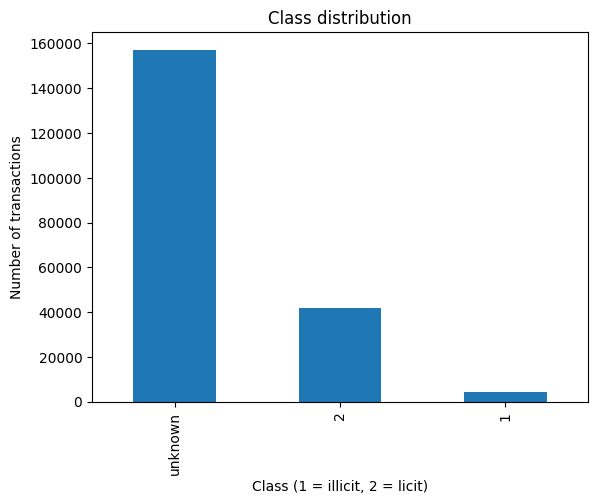

In [ ]:
import matplotlib.pyplot as plt

classes['class'].value_counts().plot(kind='bar')
plt.title('Class distribution')
plt.xlabel('Class (1 = illicit, 2 = licit)')
plt.ylabel('Number of transactions')
plt.show()